In [1]:
sitios = {
    "Aeropuerto del Cusco": (-13.5357, -71.9388),
    "Mercado de San Pedro": (-13.5214, -71.9815),
    "Sacsayhuamán": (-13.5086, -71.9817),
    "Qoricancha": (-13.5198, -71.9753),
    "Pisac": (-13.4217, -71.8497),
}

for lugar, (latitud, longitud) in sitios.items():
    print(f"{lugar}: lat={latitud}, lon={longitud}")

Aeropuerto del Cusco: lat=-13.5357, lon=-71.9388
Mercado de San Pedro: lat=-13.5214, lon=-71.9815
Sacsayhuamán: lat=-13.5086, lon=-71.9817
Qoricancha: lat=-13.5198, lon=-71.9753
Pisac: lat=-13.4217, lon=-71.8497


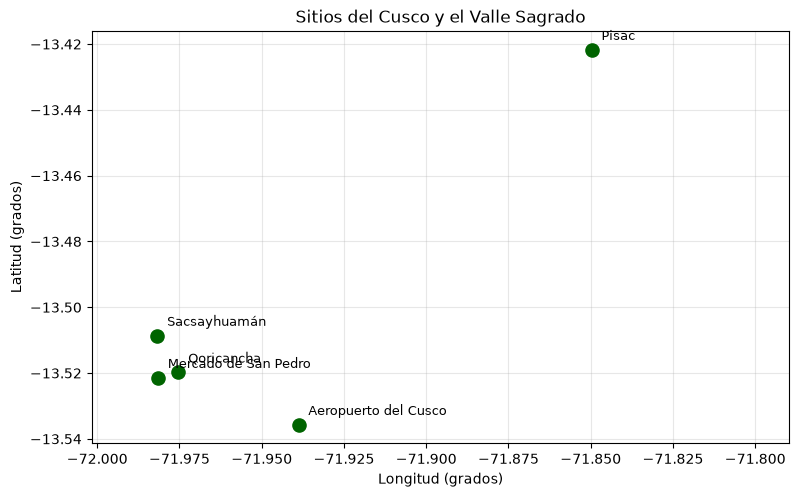

In [3]:
import matplotlib.pyplot as plt

etiquetas = list(sitios.keys())
y_lat = [c[0] for c in sitios.values()]
x_lon = [c[1] for c in sitios.values()]

fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(x_lon, y_lat, color="darkgreen", s=90, zorder=3)

for et, x, y in zip(etiquetas, x_lon, y_lat):
    ax.annotate(et, (x, y), textcoords="offset points", xytext=(7, 7), fontsize=9)

ax.set_xlim(min(x_lon) - 0.02, max(x_lon) + 0.06)  # margen para etiquetas
ax.set_xlabel("Longitud (grados)")
ax.set_ylabel("Latitud (grados)")
ax.set_title("Sitios del Cusco y el Valle Sagrado")
ax.set_aspect("equal")
ax.grid(alpha=0.3)

plt.savefig("mapa_basico.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
import math

def distancia_haversine(lat1, lon1, lat2, lon2):
    radio = 6371  # radio medio de la Tierra en km
    f1, f2 = math.radians(lat1), math.radians(lat2)
    d_fi = math.radians(lat2 - lat1)
    d_lam = math.radians(lon2 - lon1)
    a = math.sin(d_fi / 2) ** 2 + math.cos(f1) * math.cos(f2) * math.sin(d_lam / 2) ** 2
    return radio * 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))

In [5]:
origen = etiquetas[0]
lat_o, lon_o = sitios[origen]

print(f"Distancias desde {origen}:\n")
for destino in etiquetas[1:]:
    lat_d, lon_d = sitios[destino]
    km = distancia_haversine(lat_o, lon_o, lat_d, lon_d)
    print(f"  {destino}: {km:.2f} km")

Distancias desde Aeropuerto del Cusco:

  Mercado de San Pedro: 4.88 km
  Sacsayhuamán: 5.53 km
  Qoricancha: 4.32 km
  Pisac: 15.92 km


In [7]:
from itertools import combinations

pares = [
    (a, b, distancia_haversine(*sitios[a], *sitios[b]))
    for a, b in combinations(sitios, 2)
]

mas_cerca = min(pares, key=lambda p: p[2])
mas_lejos = max(pares, key=lambda p: p[2])

print(f"MÁS CERCANO: {mas_cerca[0]} y {mas_cerca[1]} -> {mas_cerca[2]:.2f} km")
print(f"MÁS LEJANO:  {mas_lejos[0]} y {mas_lejos[1]} -> {mas_lejos[2]:.2f} km")

MÁS CERCANO: Mercado de San Pedro y Qoricancha -> 0.69 km
MÁS LEJANO:  Mercado de San Pedro y Pisac -> 18.06 km


In [8]:
import json

lista_features = []
for lugar, (latitud, longitud) in sitios.items():
    lista_features.append({
        "type": "Feature",
        "properties": {"nombre": lugar},
        "geometry": {"type": "Point", "coordinates": [longitud, latitud]}  # [lon, lat]
    })

coleccion = {"type": "FeatureCollection", "features": lista_features}

with open("mis_lugares.geojson", "w", encoding="utf-8") as archivo:
    json.dump(coleccion, archivo, indent=2, ensure_ascii=False)

print("GeoJSON guardado.")

GeoJSON guardado.


In [9]:
with open("mis_lugares.geojson", "r", encoding="utf-8") as archivo:
    leido = json.load(archivo)

print(f"Features: {len(leido['features'])}")
f0 = leido["features"][0]
print(f"Primer lugar: {f0['properties']['nombre']}")
print(f"Coordenadas [lon, lat]: {f0['geometry']['coordinates']}")

Features: 5
Primer lugar: Aeropuerto del Cusco
Coordenadas [lon, lat]: [-71.9388, -13.5357]


In [11]:
ruta = {
    "type": "Feature",
    "properties": {"nombre": "Ruta Aeropuerto - Qoricancha"},
    "geometry": {
        "type": "LineString",
        "coordinates": [[-71.9388, -13.5357], [-71.9753, -13.5198]]
    }
}
coleccion["features"].append(ruta)

with open("mis_lugares.geojson", "w", encoding="utf-8") as archivo:
    json.dump(coleccion, archivo, indent=2, ensure_ascii=False)